# Setup

In [57]:
# Colab Setup
# !git clone https://github.com/fastai/course22p2.git
# %cd course22p2
# !pip install -q fastcore einops datasets timm
# import sys
# sys.path.append('/content/course22p2')
# !pip install -q k-diffusion fastcore einops datasets timm
# !pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
# !pip install -q fastcore einops datasets timm k-diffusion
# !pip install -q torcheval fastcore einops datasets timm k-diffusion
# !pip install -q numpy==1.26.4 --force-reinstall

In [58]:
# Kaggle Setup
!git clone https://github.com/fastai/course22p2.git
!pip install -q numpy --upgrade          # upgrade numpy FIRST
!pip install -q fastcore einops datasets timm k-diffusion torcheval

fatal: destination path 'course22p2' already exists and is not an empty directory.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
dctorch 0.1.2 requires numpy<2.0.0,>=1.22.3, but you have numpy 2.4.6 which is incompatible.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.1 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.4.6 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dask-cuda 26.2.0 requires cuda-core==0.3.*, but you have cuda-core 1.0.1 which is incompatible.
dask-cuda 26.2.0 requires numba-cuda<0.23.0,>=0.22.1, but

In [59]:
# Kaggle Setup
import sys
sys.path.append('/kaggle/working/course22p2')
import os
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [60]:
import math,torch
from torch import nn
from miniai.activations import *

In [61]:
import matplotlib.pyplot as plt

# Attention

    problem with convolutions:
      early layers: 3×3 kernel → only sees 3×3 neighborhood
      deep layers: receptive field grows but most weight is on nearby pixels
      result: a pixel can't easily "look" at a pixel far away

    attention solves this:
      every pixel can directly compare itself to EVERY other pixel
      regardless of distance → global receptive field in one operation

In [62]:
x = torch.rand(64, 32, 16, 16)

In [63]:
x.shape[:2]

torch.Size([64, 32])

In [64]:
# shape to -> BS, FLATTEN_SPATIAL, FEATS
t = x.view(*(x.shape[:2]), -1) ; t.shape

torch.Size([64, 32, 256])

In [65]:
t = t.transpose(1,2) ; t.shape

torch.Size([64, 256, 32])

In [66]:
ni = 32

In [67]:
sk = nn.Linear(ni,ni) # k-> keys
sq = nn.Linear(ni,ni) # q-> queries
sv = nn.Linear(ni,ni) # v -> values
proj = nn.Linear(ni,ni)

In [68]:
k = sk(t)
q = sq(t)
v = sv(t)

In [69]:
k.shape, q.shape, k.transpose(1,2).shape

(torch.Size([64, 256, 32]),
 torch.Size([64, 256, 32]),
 torch.Size([64, 32, 256]))

In [70]:
g = (q@k.transpose(1,2)) ; g.shape

torch.Size([64, 256, 256])

In [71]:
g = g.softmax(-1) ; g.shape

torch.Size([64, 256, 256])

In [72]:
g.sum(-1)[0][0]

tensor(1.0000, grad_fn=<SelectBackward0>)

In [73]:
v.shape

torch.Size([64, 256, 32])

In [74]:
g = g @ v ; g.shape

torch.Size([64, 256, 32])

In [75]:
g = proj(g) ; g.shape

torch.Size([64, 256, 32])

In [76]:
g.transpose(1,2).reshape(x.shape).shape

torch.Size([64, 32, 16, 16])

In [77]:
class SelfAttention(nn.Module):
  def __init__(self, ni):
    super().__init__()
    self.scale = math.sqrt(ni)
    self.norm = nn.GroupNorm(1, ni)
    self.k = nn.Linear(ni,ni) # k-> keys
    self.q = nn.Linear(ni,ni) # q-> queries
    self.v = nn.Linear(ni,ni) # v -> values
    self.proj = nn.Linear(ni, ni)

  def forward(self, x):
    inp = x
    n,c,h,w = x.shape
    x = self.norm(x)
    x = x.view(n,c,-1).transpose(1,2)
    q = self.q(x)
    k = self.k(x)
    v = self.v(x)
    s = (q@k.transpose(1, 2)) / self.scale
    x = s.softmax(dim=-1) @ v # softmax makes sum relation between each pixel and all the other pixels = 1
    x = self.proj(x)
    x = x.transpose(1,2).reshape(n,c,h,w)  # (64, 256, 32) -> (64, 32, 16, 16)
    return inp + x   # like in ResNet

- WHY `x @ x.T` IS NOT ENOUGH:

   - all 32 channels contribute equally to similarity

- `without projection`: compare raw pixel features directly
- `with projection`: model LEARNS how to combine the 32 features
                   before comparison

    softmax formula:   softmax(xi) = e^xi / Σe^xj

    property 1: sum = 1

    property 2: WINNER-TAKES-ALL
      because of e^ (exponential), small differences get amplified:
      
      input:   [2.0,  1.9,  0.5,  0.1]
      softmax: [0.47, 0.42, 0.08, 0.03]   ← 2.0 dominates
      
      input:   [10.0, 9.9,  0.5,  0.1]
      softmax: [0.55, 0.45, 0.00, 0.00]   ← even stronger domination


      with single-head attention + softmax, each pixel ends up
      attending to basically ONE other pixel (the most similar one)
      all other pixels get near-zero weight
      → you're not really doing "weighted average of all pixels"
      → you're just picking the single most similar pixel
      → very limited information flow

    without scaling: softmax gets values like [0, 57, 0, 23, ...]
      e^57 is astronomical → even harder winner-takes-all
      softmax becomes nearly one-hot → gradients vanisha

    dividing by sqrt(ni) brings std back to ~1 before softmax
       → softmax operates in a reasonable range

    if values are ~standard normal (mean 0, std 1):
      each product has std=1, and you're summing 32 of them
      → result has std = sqrt(32) ≈ 5.7


In [78]:
sa = SelfAttention(32)

In [79]:
ra = sa(x)
ra.shape

torch.Size([64, 32, 16, 16])

In [80]:
ra[0,0,0]

tensor([0.9140, 0.7740, 0.6335, 0.4895, 0.3617, 0.4902, 1.1033, 0.7779, 0.5555, 0.4422, 1.0108, 0.8720, 0.7630, 0.3338, 0.9098, 0.9632],
       grad_fn=<SelectBackward0>)

In [81]:
class SelfAttention(nn.Module):
    def __init__(self, ni):
        super().__init__()
        self.scale = math.sqrt(ni)
        self.norm = nn.BatchNorm2d(ni)
        self.qkv = nn.Linear(ni, ni*3)
        self.proj = nn.Linear(ni, ni)

    def forward(self, inp):
        n,c,h,w = inp.shape
        x = self.norm(inp).view(n, c, -1).transpose(1, 2)
        q,k,v = torch.chunk(self.qkv(x), 3, dim=-1)
        s = (q@k.transpose(1,2))/self.scale
        x = s.softmax(dim=-1)@v
        x = self.proj(x).transpose(1,2).reshape(n,c,h,w)
        return x+inp

Same thing but make a one big linear layer and then use `chunk` to get `q`, `k`, `v`

In [82]:
sa = SelfAttention(32)
sa(x).shape

torch.Size([64, 32, 16, 16])

In [83]:
sa(x).std(), sa(x).mean()

(tensor(0.3171, grad_fn=<StdBackward0>),
 tensor(0.5080, grad_fn=<MeanBackward0>))

# Multihead Attention

In [84]:
from einops import rearrange

In [85]:
class SelfAttentionMultiHead(nn.Module):
  def __init__(self, ni, nheads):
    super().__init__()
    self.nheads = nheads
    self.scale = math.sqrt(ni)
    self.norm = nn.BatchNorm2d(ni)
    self.qkv = nn.Linear(ni, ni*3)
    self.proj = nn.Linear(ni, ni)

  def forward(self, inp):
    n,c,h,w = inp.shape
    x = self.norm(inp).view(n, c, -1).transpose(1, 2)
    x = self.qkv(x)
    x = rearrange(x, 'n s (h d) -> (n h) s d', h=self.nheads)
    q,k,v = torch.chunk(x, 3, dim=-1)
    s = (q@k.transpose(1,2)) / self.scale
    x = s.softmax(-1) @ v
    x = rearrange(x, '(n h) s d -> n s (h d)', h=self.nheads)
    x = self.proj(x).transpose(1,2).reshape(inp.shape)
    return x + inp

    WHY single head is bad (connecting back to softmax):
      single head: ALL 32 channels compete in one softmax
      softmax picks one winner → very rigid, can't capture multiple types of relationships simultaneously

    multi-head splits channels into independent groups:
      32 channels, 4 heads → 8 channels per head
      each head picks its OWN most relevant pixel independently
      → richer information flow, multiple relationships captured


    HOW it's implemented:
      before: (B=64, S=256, C=32)
      
      step 1: expand channels into (nheads, channels_per_head)
        (64, 256, 32) → (64, 256, 4, 8)   ← split 32 into 4×8
      
      step 2: merge heads into batch dim
        (64, 256, 4, 8) → (64×4, 256, 8) = (256, 256, 8)
      
      in one line:
        rearrange(x, 'n s (h d) -> (n h) s d', h=4)
        
      then, same attention as before
      PyTorch doesn't know about heads — it just sees a bigger batch
      
      step 3: rearrange back
        (n h) s d -> n s (h d)
        merge heads back into channel dimension


    scale change: sqrt(ni/nheads) not sqrt(ni)
      because each head operates on ni/nheads channels

In [86]:
sa = SelfAttentionMultiHead(32, 4)
sx = sa(x)
sx.shape

torch.Size([64, 32, 16, 16])

In [87]:
def heads_to_batch(x, heads):
  n,sl,d = x.shape                  # (64, 256, 32)
  x = x.reshape(n, sl, heads, -1)   # (64, 256, 4, 8)
  return x.transpose(1,2).reshape(n*heads, sl, -1) #(64, 4, 256, 8) -> (256, 256, 8)

def batch_to_heads(x, heads):
  n,sl,d = x.shape # (256, 256, 8)
  x = x.reshape(-1, heads, sl, d) # (64, 4, 256, 8)
  return x.transpose(1,2).reshape(-1, sl, d*heads) # (64, 256, 4, 8)  ->  (64, 256, 32)

That is the more standard way diffusion does it, but it is the same

In [88]:
sx.mean(),sx.std()

(tensor(0.4748, grad_fn=<MeanBackward0>),
 tensor(0.3088, grad_fn=<StdBackward0>))

In [89]:
nm = nn.MultiheadAttention(32, num_heads=8, batch_first=True)
nmx,nmw = nm(t,t,t)
nmx = nmx+t

- Remember -> `batch_first=True`
- `nm(t,t,t)` -> `(query, key, value)` -> [`same tensor 3 times = self-attention`, `different tensors → cross-attention`]

    2 return values:
      nmx → the attention output  (B, S, C)
      nmw → attention weights matrix  (B, S, S)  ← the softmax result
            shows which pixels attended to which
            useful for visualization/debugging, usually ignored in training

In [90]:
nmx.mean(),nmx.std()

(tensor(0.5152, grad_fn=<MeanBackward0>),
 tensor(0.3519, grad_fn=<StdBackward0>))

# Attention in the Difffusion UNet model
- Using the `Cosine Sched`

In [91]:
os.environ['CUDA_VISIBLE_DEVICES'] = '0,1'

In [92]:
#| export
from miniai.imports import *

from einops import rearrange
from fastprogress import progress_bar

In [93]:
torch.set_printoptions(precision=4, linewidth=140, sci_mode=False)
torch.manual_seed(1)
mpl.rcParams['image.cmap'] = 'gray_r'
mpl.rcParams['figure.dpi'] = 70

import logging
logging.disable(logging.WARNING)

set_seed(42)
if fc.defaults.cpus>8: fc.defaults.cpus=8

In [94]:
xl,yl = 'image','label'
name = "zalando-datasets/fashion_mnist"
bs = 512
dsd = load_dataset(name)

In [95]:
#| export
def abar(t): return (t*math.pi/2).cos()**2
def inv_abar(x): return x.sqrt().acos()*2/math.pi #  inverse_fn return t given abar

def noisify(x0):
    device = x0.device
    n = len(x0)
    t = torch.rand(n,).to(x0).clamp(0,0.999)
    ε = torch.randn(x0.shape, device=device)
    abar_t = abar(t).reshape(-1, 1, 1, 1).to(device)
    xt = abar_t.sqrt()*x0 + (1-abar_t).sqrt()*ε
    return (xt, t.to(device)), ε

def collate_ddpm(b): return noisify(default_collate(b)[xl])
def dl_ddpm(ds): return DataLoader(ds, batch_size=bs, collate_fn=collate_ddpm, num_workers=4)

In [96]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

dl = dls.train
(xt,t),eps = b = next(iter(dl))

# Training

## Create Classes

In [97]:
def timestep_embedding(tsteps, emb_dim, max_period= 10000):
    exponent = -math.log(max_period) * torch.linspace(0, 1, emb_dim//2, device=tsteps.device)
    emb = tsteps[:,None].float() * exponent.exp()[None,:]
    emb = torch.cat([emb.sin(), emb.cos()], dim=-1)
    return F.pad(emb, (0,1,0,0)) if emb_dim%2==1 else emb

In [98]:
def pre_conv(ni, nf, ks=3, stride=1, act=nn.SiLU, norm=None, bias=True):
    layers = nn.Sequential()
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Conv2d(ni, nf, stride=stride, kernel_size=ks, padding=ks//2, bias=bias))
    return layers

In [99]:
def upsample(nf): return nn.Sequential(nn.Upsample(scale_factor=2.), nn.Conv2d(nf, nf, 3, padding=1))

In [100]:
def lin(ni, nf, act=nn.SiLU, norm=None, bias=True):
    layers = nn.Sequential()
    if norm: layers.append(norm(ni))
    if act : layers.append(act())
    layers.append(nn.Linear(ni, nf, bias=bias))
    return layers

In [101]:
# This version is giving poor results - use the cell below instead
class SelfAttention(nn.Module):
    def __init__(self, ni, attn_chans):
        super().__init__()
        self.attn = nn.MultiheadAttention(ni, ni//attn_chans, batch_first=True)
        self.norm = nn.BatchNorm2d(ni)

    def forward(self, x):
        n,c,h,w = x.shape
        x = self.norm(x).view(n, c, -1).transpose(1, 2)
        x = self.attn(x, x, x, need_weights=False)[0]
        return x.transpose(1,2).reshape(n,c,h,w)

- `attn_chans` = `ni` / `nheads` = Features at the last dim when we merge the heads and batch dims

In [102]:
# 1D attention + without the ResNet style at the end if you want you have to make it later
class SelfAttention(nn.Module):
  def __init__(self, ni, attn_chans, transpose=True):
    super().__init__()
    self.nheads = ni//attn_chans
    self.scale = math.sqrt(attn_chans)
    self.norm = nn.LayerNorm(ni)
    self.qkv = nn.Linear(ni,ni*3)
    self.proj = nn.Linear(ni, ni)
    self.t = transpose

  def forward(self, x):
      n,c,s = x.shape # n-> BS, c-> feats(channels), s-> sequence(Flattened spacials)
      if self.t: x = x.transpose(1,2)
      x = self.norm(x)          
      qkv = self.qkv(x)
      qkv = rearrange(qkv,'n s (h d) -> (n h) s d', h=self.nheads)
      q,k,v = torch.chunk(qkv, 3, dim=-1)
      s = (q@k.transpose(1,2)) / self.scale
      x = (s.softmax(-1)) @ v
      x = rearrange(x,'(n h) s d -> n s (h d) ', h=self.nheads)
      x = self.proj(x)
      if self.t: x = x.transpose(1,2)
      return x

In [103]:
class SelfAttention2D(SelfAttention):
  def forward(self, x):
    n,c,h,w = x.shape
    return super().forward(rearrange(x,'n c h w -> n c (h w)')).reshape(x.shape)

In [104]:
class EmbResBlock(nn.Module):
  def __init__(self, n_emb, ni, nf=None, act=nn.SiLU, norm=nn.BatchNorm2d, attn_chans=0):
    super().__init__()
    if nf is None : nf = ni
    self.lin_emb = nn.Linear(n_emb, nf*2) # *2 bec we make chunk later
    self.conv1 = pre_conv(ni, nf, act=act, norm=norm)
    self.conv2 = pre_conv(nf, nf, act=act, norm=norm)
    self.idconv = fc.noop if ni==nf else nn.Conv2d(ni, nf, kernel_size=1)
    self.attn = SelfAttention2D(nf, attn_chans) if attn_chans else False

  def forward(self, x, t):
    inp = x
    t_emb = self.lin_emb(F.silu(t))[:, :, None, None] # expand to have H,W dims
    x = self.conv1(x)
    scale, shift = torch.chunk(t_emb, 2, dim=1) # at feats dim, bec as prev we made *2 in lin
    x = x*(1+scale) + shift
    x = self.conv2(x)
    x = x + self.idconv(inp)
    if self.attn : x = x + self.attn(x)
    return x

In [105]:
def saved(block, obj):
  block_ = block.forward

  @wraps(block.forward)
  def _f(*args, **kwargs):
    res = block_(*args, **kwargs)
    obj.saved.append(res)
    return res

  block.forward = _f
  return block

In [141]:
class DownBlock(nn.Module):
  def __init__(self, n_emb, ni, nf, add_down=True, num_layers=1, attn_chans=0): # <- ADD: attn_chans
    super().__init__()
    self.resnets = nn.ModuleList([saved(EmbResBlock(n_emb, ni if i==0 else nf, nf, attn_chans=attn_chans), self) for i in range(num_layers)]) # <- ADD: attn_chans
    self.down = saved(nn.Conv2d(nf, nf, 3, stride=2, padding=1), self) if add_down else nn.Identity()

  def forward(self, x, t):
    self.saved = []
    for res in self.resnets : x = res(x, t)
    return self.down(x)

In [142]:
class UpBlock(nn.Module):
  def __init__(self, n_emb, ni, prev_nf, nf, add_up=True, num_layers=2, attn_chans=0): # <- ADD: attn_chans
    super().__init__()
    self.resnets = nn.ModuleList([EmbResBlock(n_emb, (prev_nf if i==0 else nf)+(ni if (i==num_layers-1) else nf), nf, attn_chans=attn_chans) for i in range(num_layers)]) #  <- ADD: attn_chans
    self.up = upsample(nf) if add_up else nn.Identity()

  def forward(self, x, t, ups):
    for resnet in self.resnets: x = resnet(torch.cat([x, ups.pop()], dim=1), t)
    return self.up(x)

In [143]:
class EmbUNetModel(nn.Module):
  def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1, attn_chans=8, attn_start=1):
    super().__init__()
    self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1) # Same spacial
    self.n_temb = nf = nfs[0]
    n_emb = nf*4
    self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d), # leaving the activation here made all the diff
                                 lin(n_emb, n_emb))
    self.downs = nn.ModuleList()
    n = len(nfs)  # instead of rewriting len(nfs) again
    for i in range(n):
      ni = nf
      nf = nfs[i]
      self.downs.append(DownBlock(n_emb, ni, nf, add_down=(i!=(n-1)), num_layers = num_layers, attn_chans=0 if i<attn_start else attn_chans))
    self.mid_block = EmbResBlock(n_emb, nfs[-1])

    rev_nfs = list(reversed(nfs))
    nf = rev_nfs[0]
    self.ups = nn.ModuleList()
    for i in range(n):
      prev_nf = nf
      nf = rev_nfs[i]
      ni = rev_nfs[min(i+1, n-1)]
      self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up= (i!=(n-1)), num_layers=num_layers+1, attn_chans=attn_chans if i<n-attn_start else 0))
    self.conv_out = pre_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)   # bias = False, bec BatchNorm

  def forward(self, inp):
    x,t = inp
    temb = timestep_embedding(t, self.n_temb)
    emb = self.emb_mlp(temb)
    x = self.conv_in(x)
    saved = [x]
    for block in self.downs: x = block(x, emb)
    saved += [p for b in self.downs for p in b.saved]
    x = self.mid_block(x, emb)
    for block in self.ups: x = block(x, emb, saved)
    return self.conv_out(x)

- Added `attn_start` because if we make `Attention` at the start when there is alot of `spacials` we are going to eat alot of `memory` so we make this as starting point to when we start adding `Attention` to `Blocks`

## Make self.saved local so that i can run the training on 2 Kaggle GPUs with no problems

In [184]:
class DownBlock(nn.Module):
  def __init__(self, n_emb, ni, nf, add_down=True, num_layers=1, attn_chans=0):
    super().__init__()
    self.resnets = nn.ModuleList([EmbResBlock(n_emb, ni if i==0 else nf, nf, attn_chans=attn_chans) for i in range(num_layers)])
    self.add_down = add_down
    self.down = nn.Conv2d(nf, nf, 3, stride=2, padding=1) if add_down else nn.Identity()

  def forward(self, x, t):
    saved = []   # Make local
    for res in self.resnets: # loop and save
      x = res(x, t)
      saved.append(x)
    x = self.down(x)
    if self.add_down: saved.append(x)
    return x, saved          # ← return it, don't store on self

Make the `saved` local not as `attr` and make it returned when we call the `block`

In [185]:
class EmbUNetModelFix(EmbUNetModel):
    def forward(self, inp):
        x,t = inp
        temb = timestep_embedding(t, self.n_temb)
        emb = self.emb_mlp(temb)
        x = self.conv_in(x)
        saved = [x]
        for block in self.downs:
            x, block_saved = block(x, emb)   # ← unpack
            saved += block_saved     # add it to saved
        x = self.mid_block(x, emb)
        for block in self.ups: x = block(x, emb, saved)
        return self.conv_out(x)

During the looping we unpack the output and add the `saved` to the `saved_list`

## Train

In [186]:
model = EmbUNetModelFix(in_channels=1, out_channels=1, nfs=(32,64,128,256), num_layers=2)

In [187]:
model = nn.DataParallel(model)

In [188]:
lr = 1e-2
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision()]
learn = Learner(model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

/kaggle/working/course22p2/miniai/accel.py:33: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  def before_fit(self, learn): self.scaler = torch.cuda.amp.GradScaler()


loss,epoch,train
0.146,0,train
0.086,0,eval
0.065,1,train
0.064,1,eval
0.052,2,train
0.073,2,eval
0.048,3,train
0.049,3,eval
0.044,4,train
0.052,4,eval


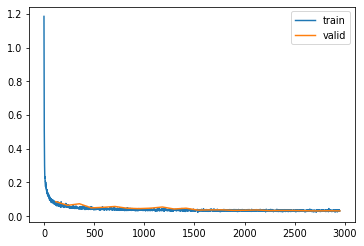

In [189]:
learn.fit(epochs)

## Sampling

In [190]:
from miniai.fid import ImageEval
cmodel = torch.load('/kaggle/input/models/seif222/data-aug2/pytorch/default/1/data_aug2.pkl', weights_only=False)
del(cmodel[8])
del(cmodel[7])

@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))*2-1 for o in b[xl]]

bs = 2048
tds = dsd.with_transform(transformi)
dls = DataLoaders.from_dd(tds, bs, num_workers=fc.defaults.cpus)

dt = dls.train
xb,yb = next(iter(dt))

ie = ImageEval(cmodel, dls, cbs=[DeviceCB()])

    that classifier  expects inputs in [-1, 1]

    diffusion model generates in [-0.5, 0.5]
    *2 → [-1, 1] to match what the FID classifier expects

    without *2: feeding wrong scale to classifier → wrong features → wrong FID score

    And of course we make the data that we compare model predictions to between [-1, 1]

In [191]:
sz = (2048,1,32,32)

In [192]:
def ddim_step(x_t, noise, abar_t, abar_t1, bbar_t, bbar_t1, eta, clamp=True):
    sig = ((bbar_t1/bbar_t).sqrt() * (1-abar_t/abar_t1).sqrt()) * eta
    x_0_hat = ((x_t-(1-abar_t).sqrt()*noise) / abar_t.sqrt())
    if clamp: x_0_hat = x_0_hat.clamp(-1,1)
    if bbar_t1<=sig**2+0.01: sig=0.  # set to zero if very small or NaN
    x_t = abar_t1.sqrt()*x_0_hat + (bbar_t1-sig**2).sqrt()*noise
    x_t += sig * torch.randn(x_t.shape).to(x_t)
    return x_0_hat,x_t

In [193]:
@torch.no_grad()
def sample(f, model, sz, steps, eta=1., clamp=True):
    model.eval()
    ts = torch.linspace(1-1/steps,0,steps)
    x_t = torch.randn(sz).cuda()
    preds = []
    for i,t in enumerate(progress_bar(ts)):
        t = t[None].cuda()
        abar_t = abar(t)
        noise = model((x_t, t))
        abar_t1 = abar(t-1/steps) if t>=1/steps else torch.tensor(1)
        x_0_hat,x_t = f(x_t, noise, abar_t, abar_t1, 1-abar_t, 1-abar_t1, eta, 1-((i+1)/100), clamp=clamp)
        preds.append(x_0_hat.float().cpu())
    return preds

In [195]:
model = model.module # Get model again on one gpu for sampling

In [196]:
preds = sample(ddim_step, model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
s.min(),s.max(),s.shape

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:06&lt;00:00]</div>

(tensor(-1.0771), tensor(1.4094), torch.Size([2048, 1, 32, 32]))

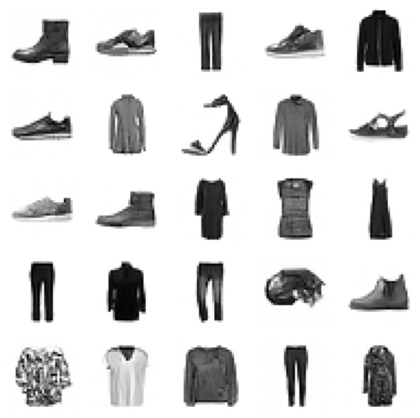

In [197]:
show_images(s[:25].clamp(-1,1), imsize=1.5)

In [198]:
ie.fid(s),ie.kid(s),s.shape

(10.654296875, 0.09168806672096252, torch.Size([2048, 1, 32, 32]))

In [199]:
preds = sample(ddim_step, model, sz, steps=100, eta=1.)
ie.fid(preds[-1]*2)

<div><progress max="100" value="100"></progress> 100.00% [100/100 02:06&lt;00:00]</div>

13.087646484375

In [200]:
preds = sample(ddim_step, model, sz, steps=50, eta=1.)
ie.fid(preds[-1]*2)

<div><progress max="50" value="50"></progress> 100.00% [50/50 01:02&lt;00:00]</div>

22.36474609375

In [201]:
preds = sample(ddim_step, model, sz, steps=50, eta=1.)
ie.fid(preds[-1]*2)

<div><progress max="50" value="50"></progress> 100.00% [50/50 01:02&lt;00:00]</div>

15.69677734375

# Conditional Model

## Classes

In [202]:
# Return label with input
def collate_ddpm(b):
    b = default_collate(b)
    (xt,t),eps = noisify(b[xl])
    return (xt,t,b[yl]),eps

In [203]:
@inplace
def transformi(b): b[xl] = [F.pad(TF.to_tensor(o), (2,2,2,2))-0.5 for o in b[xl]]

tds = dsd.with_transform(transformi)
dls = DataLoaders(dl_ddpm(tds['train']), dl_ddpm(tds['test']))

dl = dls.train
(xt,t,c),eps = b = next(iter(dl))

In [204]:
class CondUNetModel(nn.Module):
  def __init__(self,n_classes, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1):
    super().__init__()
    self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1) # Same spacial
    self.n_temb = nf = nfs[0]
    n_emb = nf*4
    self.cond_emb = nn.Embedding(n_classes, n_emb) 
    self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d), # leaving the activation here made all the diff
                                 lin(n_emb, n_emb))
    self.downs = nn.ModuleList()
    for i in range(len(nfs)):
      ni = nf
      nf = nfs[i]
      self.downs.append(DownBlock(n_emb, ni, nf, add_down=(i!=(len(nfs)-1)), num_layers = num_layers))
    self.mid_block = EmbResBlock(n_emb, nfs[-1])

    rev_nfs = list(reversed(nfs))
    nf = rev_nfs[0]
    self.ups = nn.ModuleList()
    for i in range(len(nfs)):
      prev_nf = nf
      nf = rev_nfs[i]
      ni = rev_nfs[min(i+1, len(nfs)-1)]
      self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up= (i!=(len(nfs)-1)), num_layers=num_layers+1))
    self.conv_out = pre_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)   # bias = False, bec BatchNorm

  def forward(self, inp):
    x,t,c = inp
    temb = timestep_embedding(t, self.n_temb)
    cemb = self.cond_emb(c)
    emb = self.emb_mlp(temb) + cemb
    x = self.conv_in(x)
    saved = [x]
    for block in self.downs: x = block(x, emb)
    saved += [p for b in self.downs for p in b.saved]
    x = self.mid_block(x, emb)
    for block in self.ups: x = block(x, emb, saved)
    return self.conv_out(x)

- `nn.Embedding(n_classes, n_emb) ` this is just random numbers asigned to each `class_num` and the model is going to learn that to set them far apart as for the similarity of the embedding to get lower loss
- Here `emb = self.emb_mlp(temb) + cemb` addition seems like it would destroy information but in practice the model routes around it.

## Adjust for 2 GPUs

In [205]:
class CondUNetModelFix(CondUNetModel):
    def forward(self, inp):
        x,t,c = inp
        temb = timestep_embedding(t, self.n_temb)
        cemb = self.cond_emb(c)
        emb = self.emb_mlp(temb) + cemb
        x = self.conv_in(x)
        saved = [x]
        for block in self.downs:
            x, block_saved = block(x, emb)   # ← unpack
            saved += block_saved
        x = self.mid_block(x, emb)
        for block in self.ups: x = block(x, emb, saved)
        return self.conv_out(x)

To be able to run it on 2 gpus

## Train

In [206]:
cond_model = CondUNetModelFix(10, in_channels=1, out_channels=1, nfs=(32,64,128,256), num_layers=2)

In [207]:
cond_model = nn.DataParallel(cond_model)

In [208]:
lr = 1e-2
epochs = 25
opt_func = partial(optim.Adam, eps=1e-5)
tmax = epochs * len(dls.train)
sched = partial(lr_scheduler.OneCycleLR, max_lr=lr, total_steps=tmax)
cbs = [DeviceCB(), ProgressCB(plot=True), MetricsCB(), BatchSchedCB(sched), MixedPrecision()]
learn = Learner(cond_model, dls, nn.MSELoss(), lr=lr, cbs=cbs, opt_func=opt_func)

loss,epoch,train
0.290,0,train
0.231,0,eval
0.137,1,train
0.141,1,eval
0.099,2,train
0.100,2,eval
0.074,3,train
0.085,3,eval
0.061,4,train
0.067,4,eval


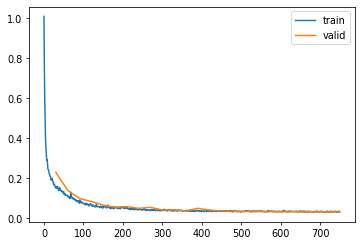

In [209]:
learn.fit(epochs)

## Sampling

In [210]:
sz = (256,1,32,32)

In [211]:
@torch.no_grad()
def cond_sample(c, f, model, sz, steps, eta=1.):
    ts = torch.linspace(1-1/steps,0,steps)
    x_t = torch.randn(sz).cuda()
    c = x_t.new_full((sz[0],), c, dtype=torch.int32)
    preds = []
    for i,t in enumerate(progress_bar(ts)):
        t = t[None].cuda()
        abar_t = abar(t)
        noise = model((x_t, t, c)) # <- ADDED: pass Class
        abar_t1 = abar(t-1/steps) if t>=1/steps else torch.tensor(1)
        x_0_hat,x_t = f(x_t, noise, abar_t, abar_t1, 1-abar_t, 1-abar_t1, eta, 1-((i+1)/100))
        preds.append(x_0_hat.float().cpu())
    return preds

Just add passing Class (c) to model, everthing else is the same

In [212]:
# Labels
lbls = dsd['train'].features[yl].names
lbls

['T - shirt / top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [214]:
cond_model = cond_model.module

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:06&lt;00:00]</div>

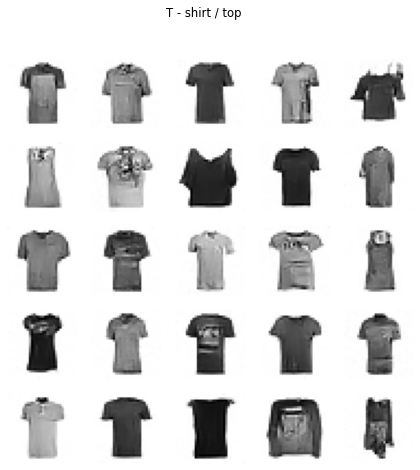

In [215]:
cid = 0
preds = cond_sample(cid, ddim_step, cond_model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
show_images(s[:25].clamp(-1,1), imsize=1.5, suptitle=lbls[cid])

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:06&lt;00:00]</div>

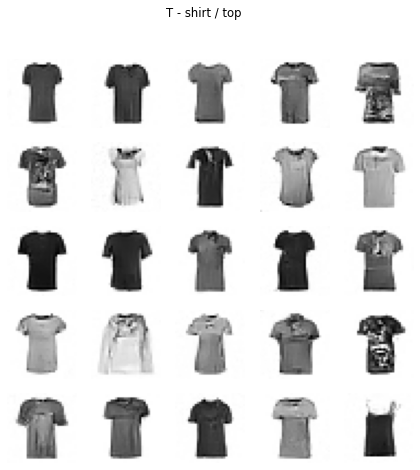

In [216]:
cid = 0
preds = cond_sample(cid, ddim_step, cond_model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
show_images(s[:25].clamp(-1,1), imsize=1.5, suptitle=lbls[cid])

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:06&lt;00:00]</div>

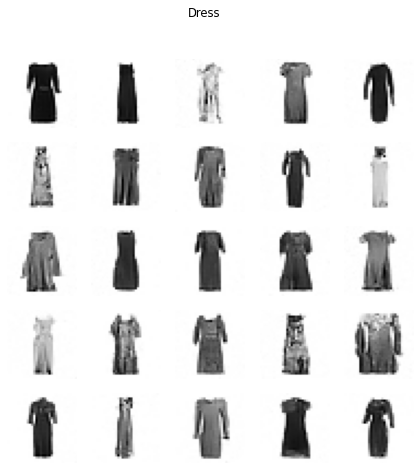

In [219]:
cid = 3
preds = cond_sample(cid, ddim_step, cond_model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
show_images(s[:25].clamp(-1,1), imsize=1.5, suptitle=lbls[cid])

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:06&lt;00:00]</div>

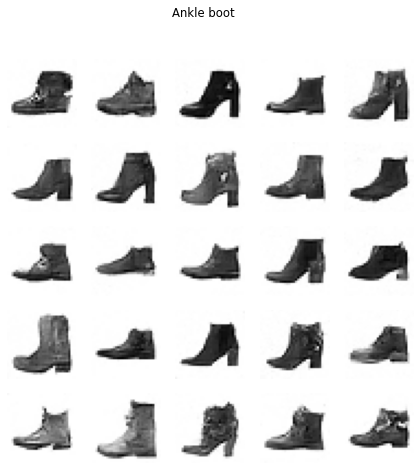

In [218]:
cid = 9
preds = cond_sample(cid, ddim_step, cond_model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
show_images(s[:25].clamp(-1,1), imsize=1.5, suptitle=lbls[cid])

<div><progress max="100" value="100"></progress> 100.00% [100/100 00:06&lt;00:00]</div>

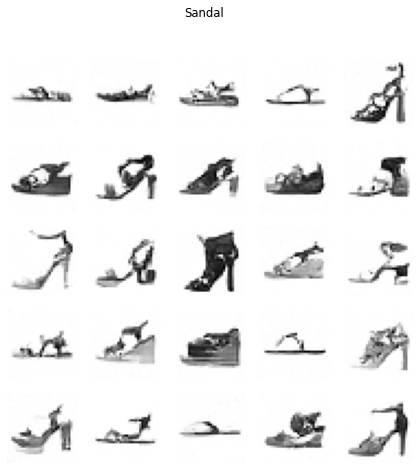

In [220]:
cid = 5
preds = cond_sample(cid, ddim_step, cond_model, sz, steps=100, eta=1.)
s = (preds[-1]*2)
show_images(s[:25].clamp(-1,1), imsize=1.5, suptitle=lbls[cid])

# Transformer

In [ ]:
class LearnEmbSS(nn.Module):
    def __init__(self, sz, ni):
        super().__init__()
        self.scale = nn.Parameter(torch.zeros(sz, ni))
        self.shift = nn.Parameter(torch.zeros(sz, ni))

    def forward(self, x): return x*self.scale + self.shift

- `LearnEmbSS` is just for making posistional embeddings or any kind of embeding really

    scale=0 means x*0=0, not identity
    "no effect" for multiplication should be 1, not 0

    BUT: transformer blocks have residual connections
    x = x + attn(norm(x))
    x = x + mlp(norm(x))
    so even if input is zeros, residuals carry signal forward
    scale learns non-zero values later

In [ ]:
def mlp_(ni, nh):
    return nn.Sequential(nn.Linear(ni, nh), nn.GELU(), nn.LayerNorm(nh), nn.Linear(nh, ni))

In [ ]:
class EmbTransformerBlk(nn.Module):
    def __init__(self, n_emb, ni, nh=None, attn_chans=8):
        super().__init__()
        if nh is None : nh=ni*4
        self.attn = SelfAttention(ni, attn_chans=attn_chans, transpose=False)
        self.mlp = mlp_(ni, nh)
        self.norm1 = nn.LayerNorm(ni)
        self.norm2 = nn.LayerNorm(ni)
        self.emb_proj = nn.Linear(n_emb, ni*2)

    def forward(self, x, t):
        emb = self.emb_proj(F.silu(t))[:, None]
        scale,shift = torch.chunk(emb, 2, dim=2)
        x = x + self.attn(self.norm1(x))
        x = x * (1+scale) + shift
        return x + self.mlp(self.norm2(x))

In [ ]:
class SimpleDiffusion(nn.Module):
    def __init__(self, in_channels=3, out_channels=3, nfs=(224,448,672,896), num_layers=1,
                 attn_chans=8, attn_start=1, n_mids=8):
        super().__init__()
        self.conv_in = nn.Conv2d(in_channels, nfs[0], kernel_size=3, padding=1)
        self.n_temb = nf = nfs[0]
        n_emb = nf*4
        self.emb_mlp = nn.Sequential(lin(self.n_temb, n_emb, norm=nn.BatchNorm1d),
                                     lin(n_emb, n_emb))
        self.downs = nn.ModuleList()
        n = len(nfs)
        for i in range(n):
            ni = nf
            nf = nfs[i]
            self.downs.append(DownBlock(n_emb, ni, nf, add_down=i!=n-1, num_layers=num_layers,
                                        attn_chans=0 if i<attn_start else attn_chans))

        self.le = LearnEmbSS(64, nf) # 64 is 8*8 final spacials at the end of down sampling
        self.mids = nn.ModuleList([EmbTransformerBlk(n_emb, nf) for _ in range(n_mids)])

        rev_nfs = list(reversed(nfs))
        nf = rev_nfs[0]
        self.ups = nn.ModuleList()
        for i in range(n):
            prev_nf = nf
            nf = rev_nfs[i]
            ni = rev_nfs[min(i+1, len(nfs)-1)]
            self.ups.append(UpBlock(n_emb, ni, prev_nf, nf, add_up=i!=n-1, num_layers=num_layers+1,
                                    attn_chans=0 if i>=n-attn_start else attn_chans))
        self.conv_out = pre_conv(nfs[0], out_channels, act=nn.SiLU, norm=nn.BatchNorm2d, bias=False)

    def forward(self, inp):
        x,t = inp
        temb = timestep_embedding(t, self.n_temb)
        emb = self.emb_mlp(temb)
        x = self.conv_in(x)
        saved = [x]
        for block in self.downs: x = block(x, emb)
        saved += [p for o in self.downs for p in o.saved]
        n,c,h,w = x.shape
        x = self.le(x.reshape(n,c,-1).transpose(1,2))
        for block in self.mids: x = block(x, emb)
        x = x.transpose(1,2).reshape(n,c,h,w)
        for block in self.ups: x = block(x, emb, saved)
        return self.conv_out(x)

We are not training and sampling using this because it will not make a difference because we didn't use Huge amounts of transformers, and we already have ResNet blocks, so it is based. Going to give almost the same performance (To make a real difference with using could possibly be like full transformer. Vision model we are going to need huge amounts of training to see the difference)

# Final Explaination

    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    1. INPUT + Q/K/V
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "input is batch, spatials, features → pass through 3 linear layers
    → keys, queries, values → model learns which features matter"     ✓

    CONCLUSION: input (B, S, C) → 3 linear layers → Q, K, V each (B, S, C)
    same shape, different learned values, channels change, pixels don't mix
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    2. Q @ K.T DIMENSIONS
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "gives spatial×spatial, like 512×512 if spatial=512"              ✓

    Q shape:    (B, 512, 32)
    K.T shape:  (B, 32,  512)   ← transpose swaps last two dims

             Q               K.T              result
        (B, 512, 32)  @  (B, 32, 512)  =  (B, 512, 512)
              ↑ inner dims match ↑
              32 == 32 ✓

    CONCLUSION: result is (B, pixels, pixels) — every pixel vs every pixel
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    3. WHAT THE DOT PRODUCT ACTUALLY DOES
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "we are literally doing dot product between each pixel and the other pixel,
    result is how similar they are"                                    ✓

    Q (rows=pixels, cols=features):        K.T (rows=features, cols=pixels):
             f0   f1   f2                           px0  px1  px2
    px0  [  0.5  0.2  0.8  ]              f0  [  0.5  0.3  0.7  ]
    px1  [  0.3  0.9  0.1  ]     @        f1  [  0.2  0.9  0.1  ]
    px2  [  0.7  0.1  0.5  ]              f2  [  0.8  0.1  0.5  ]

    result[0][1] = px0 of Q · px1 of K
                 = 0.5*0.3 + 0.2*0.9 + 0.8*0.1
                 = how similar px0 and px1 are

    result:       px0   px1   px2
      px0  [  high  med   low  ]   ← px0 most similar to itself
      px1  [  med   high  low  ]
      px2  [  low   low   high ]

    CONCLUSION: (B, S, S) matrix where entry[i][j] = similarity of pixel_i and pixel_j
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    4. LINEAR LAYER ZEROING NOISE FEATURES
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "K linear layer can learn to zero out random features,
    keep only features that have real relations"                       ✓

    CONCLUSION: Q/K learned weights → model pushes irrelevant channel weights
    toward zero → only meaningful features contribute to similarity score
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    5. SOFTMAX WINNER-TAKES-ALL
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "softmax exponential amplifies biggest relations,
    picks one or two, kills the rest, even if many matter"            ✓

    raw:      [8.2,  0.5,  0.4,  0.3]
    softmax:  [0.97, 0.01, 0.01, 0.01]  ← one winner dominates

    CONCLUSION: softmax means each pixel effectively attends to 1-2 others max
    → information bottleneck → reason multi-head is needed
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    6. @ V — WHAT ACTUALLY HAPPENS
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "multiply relation matrix by V to return to original size,
    V is learnable not raw input,
    relation between px0 and px1 gets multiplied by px1's features in V"  ✓

    concrete example:
      weights (after softmax) for px0:  [0.97, 0.02, 0.01]
                                          ↑px0  ↑px1  ↑px2

      V:         f0    f1    f2
        px0  [  0.5   0.2   0.8  ]
        px1  [  0.3   0.9   0.1  ]
        px2  [  0.7   0.1   0.5  ]

      new_px0 = 0.97 * [0.5, 0.2, 0.8]   ← V[px0] scaled by how much px0 attends to itself
               + 0.02 * [0.3, 0.9, 0.1]  ← V[px1] scaled by how much px0 attends to px1
               + 0.01 * [0.7, 0.1, 0.5]  ← V[px2] scaled by how much px0 attends to px2
              = weighted average of all pixel VALUES weighted by similarity

    result shape: (B, 512, 32) ← back to original shape
    each pixel is now a blend of other pixels' V values
    weighted by how similar they are


    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    7. PROJECTION LAYER
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "another linear layer on top, just to refine output more"          ✓

    CONCLUSION: Linear(C, C) after @V → same shape, more learnable capacity
    model can rescale/recombine channels of attention output
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    8. RESNET-STYLE ADDITION
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "attention output scales signal a lot, so add to original
    like ResNet, model learns to route around it"                      ✓

    "feels like concatenate would be better but model routes around addition"
    this is correct intuition — addition works because model has
    enough capacity to learn which signal matters where

    CONCLUSION: output = input + attention_result
    keeps original signal, attention adds refinement on top
    model starts barely using attention (weights near zero) and grows
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    9. MULTI-HEAD — WHY
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "all features mixed into one relation number → can't compress
    32 rich features with positive AND negative correlations into one number
    → cancels out, becomes noise"                                      ✓

    "so split features into heads, fewer features per head,
    each head gets its own independent relation"                       ✓

    "treat heads as extra batch items so they don't interact"          ✓

    your number example got confused but the concept is correct:
      32 channels, 4 heads → 8 channels per head
      batch 64 → batch 64×4 = 256 (heads merged into batch)

    CONCLUSION: multi-head = split channel dim into H groups,
    each group does independent attention, H different pixel relationships captured
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    10. REARRANGING BACK — NO INFORMATION LOSS
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "I feel like it could be taking average"                           ✗ WRONG

    "Does it just move? same numbers, don't compress anything"         ✓ CORRECT

    rearrange (256, 256, 8) → (64, 256, 32):
      just moves numbers to different positions in tensor
      NO averaging, NO compression, NO information loss
      same values, different shape

    "32 features at end = 8 features from each of 4 heads"            ✓ CORRECT
      head1 output: 8 channels → slots 0-7
      head2 output: 8 channels → slots 8-15
      head3 output: 8 channels → slots 16-23
      head4 output: 8 channels → slots 24-31

    CONCLUSION: rearrange = pure reshape, zero information lost
    final 32 channels = concatenation of all heads' outputs
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    11. TRANSFORMER BLOCK
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "attention + MLP, normalization, scale+shift from timestep,
    skip connections on both attention and MLP"                        ✓

    exact order in EmbTransformerBlk:
      1. emb_proj(silu(t)) → scale, shift    ← timestep conditioning
      2. x = x + attn(norm1(x))              ← attention + skip
      3. x = x*(1+scale) + shift             ← timestep scale+shift
      4. x = x + mlp(norm2(x))              ← MLP + skip

    CONCLUSION: transformer block = attention(rows) + MLP(columns) + norms + skips
    with timestep injection via scale+shift between them
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    12. LearnEmbSS = POSITIONAL EMBEDDING
    ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
    "self.le is learned embeddings, makes scale and shift,
    standalone thing, this IS the positional embedding"                ✓

    "adds to each specific pixel its own specific number
    so same channel values at different positions look different"      ✓

    "model learns which position is bigger or smaller"                 ✓

      scale shape: (64, nf) = one scale per spatial position per channel
      shift shape: (64, nf) = one shift per spatial position per channel

      position 0:   x * scale[0] + shift[0]   ← unique transform
      position 47:  x * scale[47] + shift[47] ← different unique transform

    initialized to zeros → starts with no positional influence
    → grows through backprop as model learns positions matter

    CONCLUSION: LearnEmbSS = learned positional embedding
    gives each pixel a unique learned identity before attention
    so attention can learn position-dependent relationships